## Visualizzazione prima scansione 3D

In [36]:
import os 
import glob
import nibabel as nib
import matplotlib.pyplot as plt 
import numpy as np
from nilearn import datasets, image, plotting

# 1. Percorso base della cartella del soggetto 
base_dir = r'C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw'

# 2. Cerca qualsiasi file .hdr, .img, .nii o .nii.gz dentro la cartella di OAS1_0001_MR1
pattern = os.path.join(base_dir, '**', 'OAS1_0001_MR1', '**', '*.*')
all_files = glob.glob(pattern, recursive=True)

# Filtra solo i file con estensione di imaging
img_paths = [f for f in all_files if f.endswith(('.hdr', '.nii', '.nii.gz'))]

# Controllo sicurezza
if not img_paths:
    print("Nessun file trovato! Verifica la struttura della cartella.")
else:
    print(f"Trovati {len(img_paths)} file di imaging.")
    print("Ecco i file disponibili:")
    for idx, path in enumerate(img_paths):
        print(f"[{idx}] {path}")


Trovati 8 file di imaging.
Ecco i file disponibili:
[0] C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw\disc1\OAS1_0001_MR1\FSL_SEG\OAS1_0001_MR1_mpr_n4_anon_111_t88_masked_gfc_fseg.hdr
[1] C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw\disc1\OAS1_0001_MR1\PROCESSED\MPRAGE\SUBJ_111\OAS1_0001_MR1_mpr_n4_anon_sbj_111.hdr
[2] C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw\disc1\OAS1_0001_MR1\PROCESSED\MPRAGE\T88_111\OAS1_0001_MR1_mpr_n4_anon_111_t88_gfc.hdr
[3] C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw\disc1\OAS1_0001_MR1\PROCESSED\MPRAGE\T88_111\OAS1_0001_MR1_mpr_n4_anon_111_t88_masked_gfc.hdr
[4] C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw\disc1\OAS1_0001_MR1\RAW\OAS1_0001_MR1_mpr-1_anon.hdr
[5] C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw\disc1\OAS1_0001_MR1\RAW\OAS1_0001_MR1_mpr-2_anon.hdr
[6] C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw\disc1\OAS1_0001_MR1\RAW\OAS1_0001

In [26]:
# Seleziona il primo file di imaging (preferibilmente in PROCESSED se presente)
processed_files = [f for f in img_paths if 'PROCESSED' in f]
target_file = processed_files[0] if processed_files else img_paths[0]

print(f"File selezionato per la visualizzazione:\n{target_file}\n")

File selezionato per la visualizzazione:
C:\Users\filip\Documents\neuroimaging-oasis-pipeline\data\raw\disc1\OAS1_0001_MR1\PROCESSED\MPRAGE\SUBJ_111\OAS1_0001_MR1_mpr_n4_anon_sbj_111.hdr



In [28]:
# 3. Caricamento del volume 3D
mri_img = nib.load(target_file)
mri_data = mri_img.get_fdata()

# 4. Informazioni sulle dimensioni e sul tipo di dati
print(f"Dimensioni del volume 3D (Shape): {mri_data.shape}")
print(f"Risoluzione / Voxel Size (Header): {mri_img.header.get_zooms()}")
print(f"Tipo di dati (Dtype): {mri_data.dtype}\n")

Dimensioni del volume 3D (Shape): (256, 256, 160, 1)
Risoluzione / Voxel Size (Header): (np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(0.0))
Tipo di dati (Dtype): float64



Dimensioni del volume 3D originario: (256, 256, 160)


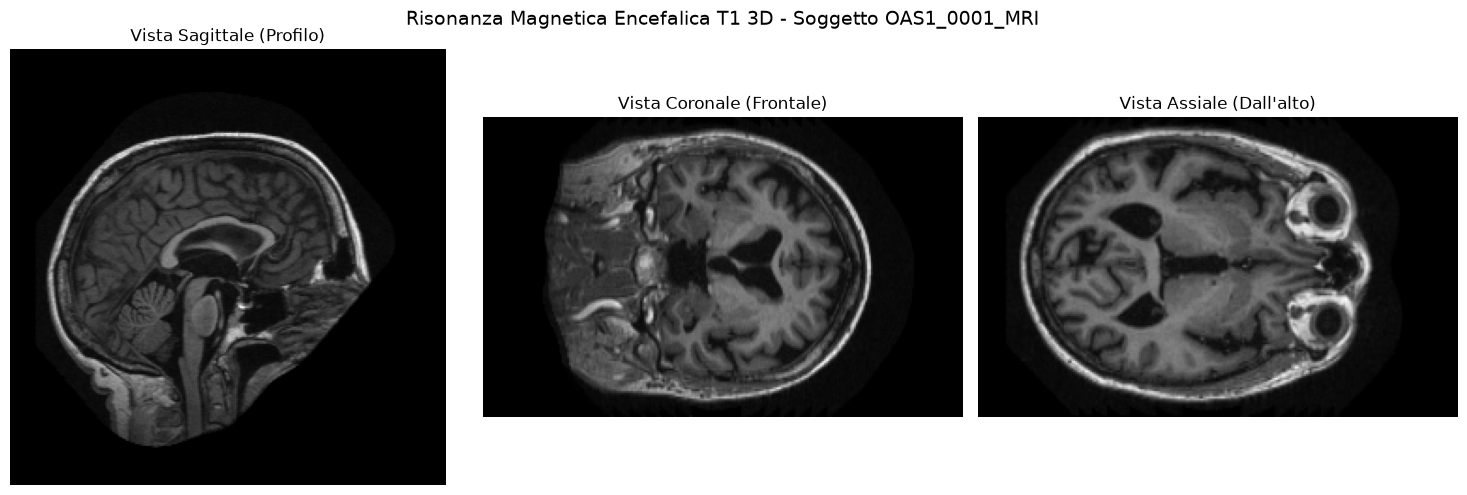

In [27]:
# 5. Estrazione delle tre sezioni centrali lungo i tre assi ortogonali
# Gestiamo la rimozione di un'eventuale quarta dimensione (es. canale o tempo)
if mri_data.ndim == 4:
    mri_data = mri_data[:, :, :, 0]

print(f"Dimensioni del volume 3D originario: {mri_data.shape}")

# Estrazione e riallineamento visivo manuale per OASIS-1 (.img/.hdr)
# Sagittale (Profilo): asse 2, rotato di 90 gradi
slice_sag = mri_data[:, :, mri_data.shape[2] // 2]
slice_sag_aligned = np.rot90(slice_sag, 1)

# Coronale (Frontale): asse 0, rotato e invertito
slice_cor = mri_data[mri_data.shape[0] // 2, :, :]
slice_cor_aligned = np.rot90(slice_cor, 1)

# Assiale (Orizzontale/Dall'alto): asse 1, rotato
slice_axi = mri_data[:, mri_data.shape[1] // 2, :]
slice_axi_aligned = np.rot90(slice_axi, 1)

# 6. Visualizzazione grafica a 3 viste con Matplotlib
fig, axes = plt.subplots(1, 3, figsize=(15,5))

# [0] Vista Sagittale (Profilo)
axes[0].imshow(slice_sag_aligned, cmap='gray')
axes[0].set_title('Vista Sagittale (Profilo)')
axes[0].axis('off')

# [1] Vista Coronale (Frontale/Dietro-Avanti)
axes[1].imshow(slice_cor_aligned, cmap='gray')
axes[1].set_title('Vista Coronale (Frontale)')
axes[1].axis('off')

# [2] Vista Assiale (Dall'alto)
axes[2].imshow(slice_axi_aligned, cmap='gray')
axes[2].set_title('Vista Assiale (Dall\'alto)')
axes[2].axis('off')

plt.suptitle('Risonanza Magnetica Encefalica T1 3D - Soggetto OAS1_0001_MRI', fontsize=14)
plt.tight_layout()
plt.show()